# Colossus surroundings versus Brownsville, Tennessee
2020–31 October 2026. Run cells in order in Google Colab.

**Brownsville is a provisional comparison, not a verified AI-free control.** A public inventory reports no coordinate-backed project within the city boundary, but absence from an inventory does not prove absence. Source: https://watchpennies.com/tennessee/haywood-county-tn/brownsville-tn/data-centers (reviewed 31 October 2026). Approximate city center: 35.59056, -89.26083. See https://en.wikipedia.org/wiki/Brownsville%2C_Tennessee.

Compare 500 m–2 km rings around the approximate Colossus center and Brownsville center. Excluding the central 500 m emphasizes surroundings, but does not delineate the facility boundary. Both rings have equal geometry, not necessarily matched vegetation/buildings. These are local study areas, not entire city averages.

Use identical processing and retain exact dates with usable observations in both locations. Few matching dates may remain; do not interpret missing observations as zero. This is descriptive surface-temperature analysis, not a causal estimate or air-temperature measurement.

In [1]:
%pip -q install earthengine-api geemap pandas matplotlib

In [2]:
import ee, geemap, pandas as pd, numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import json, hashlib, time, zipfile
from pathlib import Path
from IPython.display import display
from google.colab import files, output
output.enable_custom_widget_manager()
ee.Authenticate()
ee.Initialize(project="ee-project-ntu-512407")
START, END = "2020-01-01", "2026-11-01"
MIN_MONTH_DAYS = 2
MIN_VALID_FRACTION = 0.30 # Exploratory screen: valid grid pixels / whole ring area
INNER_M, OUTER_M = 500, 2000
locations = {
    "Colossus": [-90.15639,35.06000],
    "Brownsville": [-89.26083,35.59056]
}
regions = {}
for name,coords in locations.items():
    p=ee.Geometry.Point(coords)
    regions[name]=p.buffer(OUTER_M).difference(p.buffer(INNER_M),1)
    m=geemap.Map(center=coords[::-1],zoom=13)
    m.add_basemap("SATELLITE")
    m.addLayer(ee.FeatureCollection([ee.Feature(regions[name])]).style(
        color="ffff00",fillColor="00000000",width=2),{},name+" study ring")
    m.addLayer(p,{"color":"cyan"},name+" approximate center")
    display(m)

Map(center=[35.06, -90.15639], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topri…

Map(center=[35.59056, -89.26083], controls=(WidgetControl(options=['position', 'transparent_bg'], position='to…

## Calculate one image at a time
Progress is saved in the Colab runtime. Rerun this cell to resume an interrupted run. Identical cloud, shadow, snow, water and saturation masks are applied to both areas. The 30% coverage threshold is an explicit exploratory choice; changing valid pixel footprints can still bias comparisons.

In [3]:
def prepare(im):
    qa=im.select("QA_PIXEL")
    mask=qa.bitwiseAnd(63).eq(0).And(qa.bitwiseAnd(128).eq(0)).And(im.select("QA_RADSAT").eq(0))
    return (im.select("ST_B10").multiply(.00341802).add(149).subtract(273.15)
        .rename("LST").updateMask(mask)
        .copyProperties(im,["system:time_start","LANDSAT_PRODUCT_ID"]))
raw=(ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
     .merge(ee.ImageCollection("LANDSAT/LC09/C02/T1_L2"))
     .filterDate(START,END).filter(ee.Filter.eq("PROCESSING_LEVEL","L2SP")))
config={"version":1,"start":START,"end":END,"locations":locations,
        "inner":INNER_M,"outer":OUTER_M,"mask":"qa63_water128_radsat"}
all_rows=[]
for name,region in regions.items():
    c=raw.filterBounds(region).map(prepare).sort("system:time_start")
    manifest=c.aggregate_array("LANDSAT_PRODUCT_ID").getInfo()
    key=hashlib.sha256(json.dumps([config,name,manifest],sort_keys=True).encode()).hexdigest()[:16]
    path=Path(f"city_cache_{key}.json")
    cache=json.loads(path.read_text()) if path.exists() else {}
    images=c.toList(len(manifest))
    print(name,len(manifest),"candidate scenes;",len(cache),"cached")
    area=region.area(1).getInfo()
    for i in range(len(manifest)):
        if str(i) not in cache:
            im=ee.Image(images.get(i))
            stats=im.reduceRegion(
                reducer=ee.Reducer.mean().combine(ee.Reducer.count(),sharedInputs=True),
                geometry=region,scale=30,crs="EPSG:32616",
                maxPixels=100000000,tileScale=4)
            result=ee.Dictionary({"date":im.date().format("YYYY-MM-dd"),
                "temperature_C":stats.get("LST_mean"),"pixels":stats.get("LST_count")})
            for attempt in range(4):
                try:
                    value=result.getInfo()
                    break
                except ee.EEException as e:
                    if not any(t in str(e).lower() for t in ["429","too many concurrent","too many requests"]) or attempt==3:
                        raise
                    time.sleep(15*(attempt+1))
            cache[str(i)]=value
            path.write_text(json.dumps(cache))
        row=dict(cache[str(i)])
        row.update(location=name,coverage_fraction=(row.get("pixels") or 0)*900/area)
        all_rows.append(row)
        if (i+1)%10==0 or i+1==len(manifest):
            print(name,f"{i+1}/{len(manifest)}")
scenes=pd.DataFrame(all_rows)
scenes.to_csv("City_comparison_all_scenes.csv",index=False)
usable=scenes.dropna(subset=["temperature_C"]).copy()
usable=usable[usable.coverage_fraction>=MIN_VALID_FRACTION]
usable["date"]=pd.to_datetime(usable["date"])
daily=(usable.groupby(["date","location"]).temperature_C.mean()
       .unstack("location").reindex(columns=list(locations)))
print("Usable dates before pairing:",daily.notna().sum().to_dict())
paired=daily.dropna().copy()
if paired.empty:
    raise ValueError("No matching usable dates. Inspect coverage and acquisition dates; no city comparison can be drawn from this run.")
paired["difference_C"]=paired["Colossus"]-paired["Brownsville"]
paired.to_csv("City_comparison_paired_dates.csv")
print("Exact matching dates:",len(paired))
print("Latest paired observation:",paired.index.max().date())

Colossus 227 candidate scenes; 0 cached
Colossus 10/227
Colossus 20/227
Colossus 30/227
Colossus 40/227
Colossus 50/227
Colossus 60/227
Colossus 70/227
Colossus 80/227
Colossus 90/227
Colossus 100/227
Colossus 110/227
Colossus 120/227
Colossus 130/227
Colossus 140/227
Colossus 150/227
Colossus 160/227
Colossus 170/227
Colossus 180/227
Colossus 190/227
Colossus 200/227
Colossus 210/227
Colossus 220/227
Colossus 227/227
Brownsville 582 candidate scenes; 0 cached
Brownsville 10/582
Brownsville 20/582
Brownsville 30/582
Brownsville 40/582
Brownsville 50/582
Brownsville 60/582
Brownsville 70/582
Brownsville 80/582
Brownsville 90/582
Brownsville 100/582
Brownsville 110/582
Brownsville 120/582
Brownsville 130/582
Brownsville 140/582
Brownsville 150/582
Brownsville 160/582
Brownsville 170/582
Brownsville 180/582
Brownsville 190/582
Brownsville 200/582
Brownsville 210/582
Brownsville 220/582
Brownsville 230/582
Brownsville 240/582
Brownsville 250/582
Brownsville 260/582
Brownsville 270/582
Brow

## Monthly and yearly averages
Both locations use the same paired observation dates. Months with fewer than two dates are left blank. Yearly means weight each paired day equally; seasonal sampling is uneven and 2026 is incomplete. No missing months are filled. A positive difference means Colossus surroundings were warmer, not that AI caused the difference.

location,Colossus,Brownsville,difference_C,valid_days,months_observed,period
year,,,,,,
2020,27.97,28.13,-0.16,11,8,Calendar-year window
2021,27.13,25.63,1.50,16,10,Calendar-year window
2022,27.59,27.10,0.49,17,11,Calendar-year window
2023,26.20,25.99,0.21,19,11,Calendar-year window
2024,29.85,28.10,1.75,21,9,Calendar-year window
2025,25.33,24.00,1.33,21,12,Calendar-year window
2026,32.40,30.22,2.18,18,9,YTD through 31 Oct


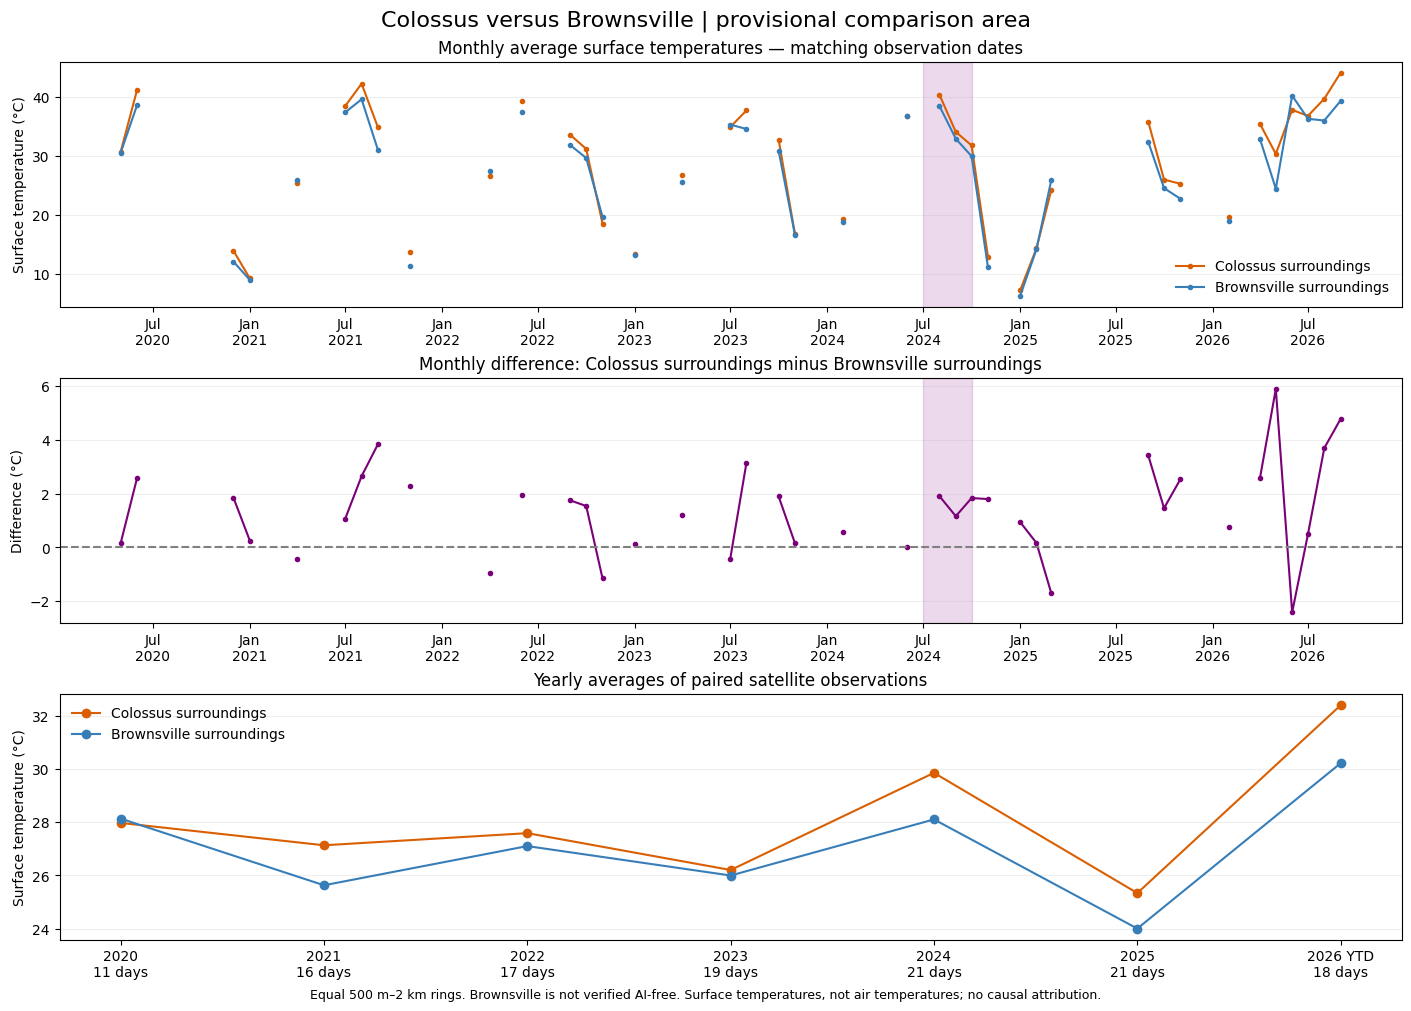

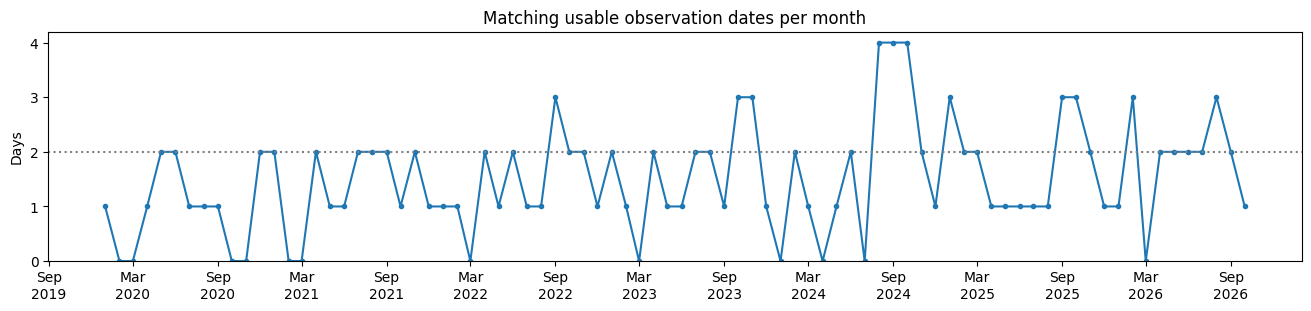

In [4]:
monthly=paired.resample("MS").mean()
monthly["valid_days"]=paired["difference_C"].resample("MS").count()
monthly=monthly.reindex(pd.date_range(START,pd.Timestamp(END)-pd.Timedelta(days=1),freq="MS"))
monthly.index.name="month"
monthly["valid_days"]=monthly["valid_days"].fillna(0).astype(int)
monthly.loc[monthly.valid_days<MIN_MONTH_DAYS,list(paired.columns)]=np.nan
yearly=paired.groupby(paired.index.year).mean().reindex(range(2020,2027))
yearly.index.name="year"
yearly["valid_days"]=paired.groupby(paired.index.year).size().reindex(yearly.index,fill_value=0)
yearly["months_observed"]=[paired[paired.index.year==y].index.month.nunique() for y in yearly.index]
yearly["period"]=["YTD through 31 Oct" if y==2026 else "Calendar-year window" for y in yearly.index]
monthly.to_csv("City_comparison_monthly.csv")
yearly.to_csv("City_comparison_yearly.csv")
display(yearly.round(2))

fig,axs=plt.subplots(3,1,figsize=(14,10),layout="constrained")
for name,color in [("Colossus","#d95f02"),("Brownsville","#377eb8")]:
    axs[0].plot(monthly.index,monthly[name],"-o",color=color,markersize=3,label=name+" surroundings")
    axs[2].plot(yearly.index,yearly[name],"-o",color=color,label=name+" surroundings")
axs[1].plot(monthly.index,monthly.difference_C,"-o",color="#7a0177",markersize=3)
axs[1].axhline(0,color="gray",linestyle="--")
for ax in axs[:2]:
    ax.axvspan(pd.Timestamp("2024-07-01"),pd.Timestamp("2024-10-01"),
               alpha=.15,color="purple")
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
axs[0].set(title="Monthly average surface temperatures — matching observation dates",ylabel="Surface temperature (°C)")
axs[1].set(title="Monthly difference: Colossus surroundings minus Brownsville surroundings",ylabel="Difference (°C)")
axs[2].set(title="Yearly averages of paired satellite observations",ylabel="Surface temperature (°C)")
axs[2].set_xticks(yearly.index)
axs[2].set_xticklabels([f"{y}"+(" YTD" if y==2026 else "")+
    f"\n{int(yearly.loc[y,'valid_days'])} days" for y in yearly.index])
for ax in axs:
    ax.grid(axis="y",alpha=.2)
axs[0].legend(frameon=False)
axs[2].legend(frameon=False)
fig.suptitle("Colossus versus Brownsville | provisional comparison area",fontsize=16)
fig.supxlabel("Equal 500 m–2 km rings. Brownsville is not verified AI-free. Surface temperatures, not air temperatures; no causal attribution.",fontsize=9)
fig.savefig("Colossus_vs_Brownsville.png",dpi=250,bbox_inches="tight")
plt.show()

coverage_fig,ax=plt.subplots(figsize=(13,3),layout="constrained")
ax.plot(monthly.index,monthly.valid_days,"-o",markersize=3)
ax.axhline(MIN_MONTH_DAYS,color="gray",linestyle=":")
ax.set(title="Matching usable observation dates per month",ylabel="Days",ylim=(0,None))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
coverage_fig.savefig("City_comparison_coverage.png",dpi=200)
plt.show()

In [5]:
Path("City_comparison_settings.json").write_text(json.dumps({
    **config,"minimum_coverage_fraction":MIN_VALID_FRACTION,
    "minimum_monthly_days":MIN_MONTH_DAYS,"pairing":"exact date",
    "control_status":"Brownsville provisional; not verified AI-free"
},indent=2))
with zipfile.ZipFile("Colossus_vs_Brownsville_results.zip","w",zipfile.ZIP_DEFLATED) as z:
    for p in ["Colossus_vs_Brownsville.png","City_comparison_coverage.png",
        "City_comparison_monthly.csv","City_comparison_yearly.csv",
        "City_comparison_paired_dates.csv","City_comparison_all_scenes.csv",
        "City_comparison_settings.json"]:
        z.write(p)
files.download("Colossus_vs_Brownsville_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Limits and next steps
A random city is not automatically a suitable control. Differences in climate, land cover, urban density and vegetation remain even with same-date observations and equal ring sizes. Check imagery and pre-2024 trends before interpreting post-startup differences. An apparent temperature gap is not evidence that AI caused warming. The comparison ring must be checked for other heat sources and data centers.

Source for Landsat scaling and masks: https://developers.google.com/earth-engine/datasets/catalog/LANDSAT_LC09_C02_T1_L2
This notebook's syntax was checked locally. Live Earth Engine processing has not been run by the assistant.